# Anomaly detection on images with reconstruction models

Image anomaly detection is aimed at identifying abnormal images in a dataset with a majority of normal images.
The domain is called "Image Anomaly Detection" or "Visual Anomaly Detection".

In this notebook we demonstrate IAD using the public dataset Fashion-MNIST created by Zalando. The dataset is originally created for image classification task. It thus includes 10 classes of images of clothing objects. To use it for an AD task we work in two setups:
1. One vs. One (OVO): one class is defined as the normal (target) class and another class (the abnormal class) is used to seed anomalies into a dataset with a majority of images from the target class.  
2. One vs. all (OVA): one object class is defined as the normal (target) class and all other 9 classes are used to seed anomalies in a dataset composed of a majority of images from the target class.




# 1. DATASET - Fashion MNIST
Fashion-MNIST is a dataset of Zalando's article images—consisting of a training set of 60k examples and a test set of 10,000 examples. Each example is a 28x28 grayscale image, associated with a label from 10 classes



<img src="https://github.com/buehlpa/Anomaly_Detection_Tutorial/blob/main/figures/fmnist_samples_5.png?raw=true" width="800" />

More information: check out the original repo @  https://github.com/zalandoresearch/fashion-mnist

In [ ]:
# @title FMNIST in TSNE 2d Representation
import folium
from PIL import Image
import requests
from io import BytesIO

# Load the image from the URL
url = 'https://github.com/buehlpa/Anomaly_Detection_Tutorial/blob/main/figures/tsne_images_features_all.png?raw=true'  # Replace with your image URL
response = requests.get(url)
img = Image.open(BytesIO(response.content))

# Create a folium map with a larger display size and no tiles
m = folium.Map(location=[0, 0], zoom_start=2, width='70%', height='800px', tiles=None)

# Set the background color to black using custom CSS
m.get_root().html.add_child(folium.Element('''<style>.leaflet-container {background: black;}</style>'''))

# Overlay the image on the map
folium.raster_layers.ImageOverlay(
    image=url,
    bounds=[[-90, -180], [90, 180]],
    opacity=1,
).add_to(m)

# Display the map with the image overlay
m


## Think

Above is the 2D representation of the trainingset of F-MNIST, every point has the according original image attached for a visual interpretation.


- Zoom in and explore the representation , can you spot the different clusters?
- Which classes do you expect to be separable the easiest? which might be harder?

############################################
# Class names
############################################

class_names

    0. "T-Shirt/Top",    # 0
    1. "Trouser",        # 1
    2. "Pullover",       # 2
    3. "Dress",          # 3
    4. "Coat",           # 4
    5. "Sandal",         # 5
    6. "Shirt",          # 6
    7. "Sneaker",        # 7
    8. "Bag",            # 8
    9. "Ankle Boot"      # 9


# PCA on the raw pixels

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from tensorflow.keras.datasets import fashion_mnist
from google.colab import files

## Train PCA on the normal class

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
trainset size: 6000 , clean testset size: 10000
Training MSE: 0.0004187996083639185
Testing MSE: 0.0014451256679486534


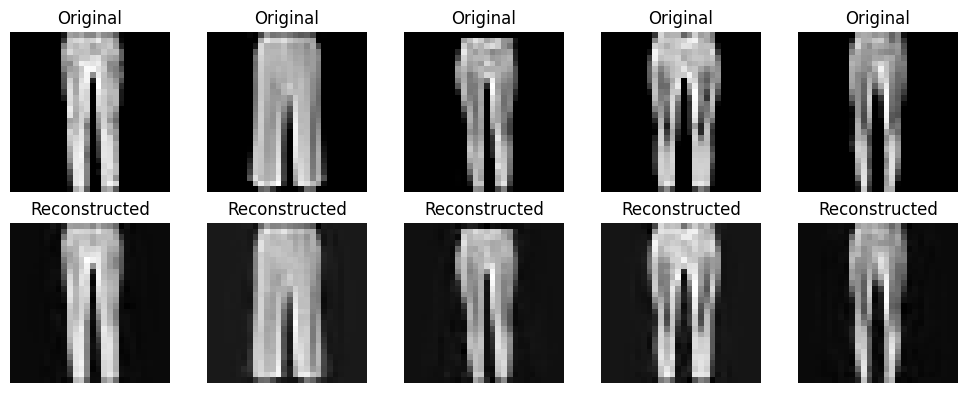

In [ ]:
# Select a specific article class to consider as "normal" (e.g., class 0: T-shirts/tops, class 1: trousers)
selected_class = 1
other_classes = [2,3,4,6]#[c for c in range(10) if c != selected_class]
# anomaly ration in the test set
anomaly_ratio = 0.3
# Number of principal components to keep in the PCA reconstruction model
n_components = 130

# Do we want to accelerate the feature extraction by reducing the train and test set sizes?
reduce_size = True


# Load Fashion MNIST data
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

if reduce_size:
  # Sample the data to reduce size by a factor of 10
  train_indices = np.random.choice(len(x_train), len(x_train) //10 , replace=False)
  test_indices = np.random.choice(len(x_test), len(x_test) // 1, replace=False)

  x_train = x_train[train_indices]
  y_train = y_train[train_indices]
  x_test = x_test[test_indices]
  y_test = y_test[test_indices]


print('trainset size:',len(y_train), ', clean testset size:',len(y_test))
# Normalize the pixel values to the range [0, 1]
x_train = x_train / 255.0
x_test = x_test / 255.0

# Reshape the images to vectors
x_train_flat = x_train.reshape(x_train.shape[0], -1)
x_test_flat = x_test.reshape(x_test.shape[0], -1)

# train on the selected class
x_train_class = x_train_flat[y_train == selected_class]
x_test_class = x_test_flat[y_test == selected_class]

# Fit PCA model on the selected class
pca = PCA(n_components=n_components)
pca.fit(x_train_class)

# Transform the data to the PCA space and then back to reconstruct
x_train_pca = pca.transform(x_train_class)
x_train_reconstructed = pca.inverse_transform(x_train_pca)

x_test_pca = pca.transform(x_test_class)
x_test_reconstructed = pca.inverse_transform(x_test_pca)

# Calculate reconstruction error
train_mse = mean_squared_error(x_train_class, x_train_reconstructed)
test_mse = mean_squared_error(x_test_class, x_test_reconstructed)
print(f"Training MSE: {train_mse}")
print(f"Testing MSE: {test_mse}")

# Visualize original vs reconstructed images
n_images = 5
plt.figure(figsize=(10, 4))

for i in range(n_images):
    # Original image
    plt.subplot(2, n_images, i + 1)
    plt.imshow(x_test_class[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Original")

    # Reconstructed image
    plt.subplot(2, n_images, i + 1 + n_images)
    plt.imshow(x_test_reconstructed[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Reconstructed")

plt.tight_layout()
plt.show()


## Test on a testset with anomalies

Mixed testset size: 1300
Test MSE with anomalies: 0.004299989947932971


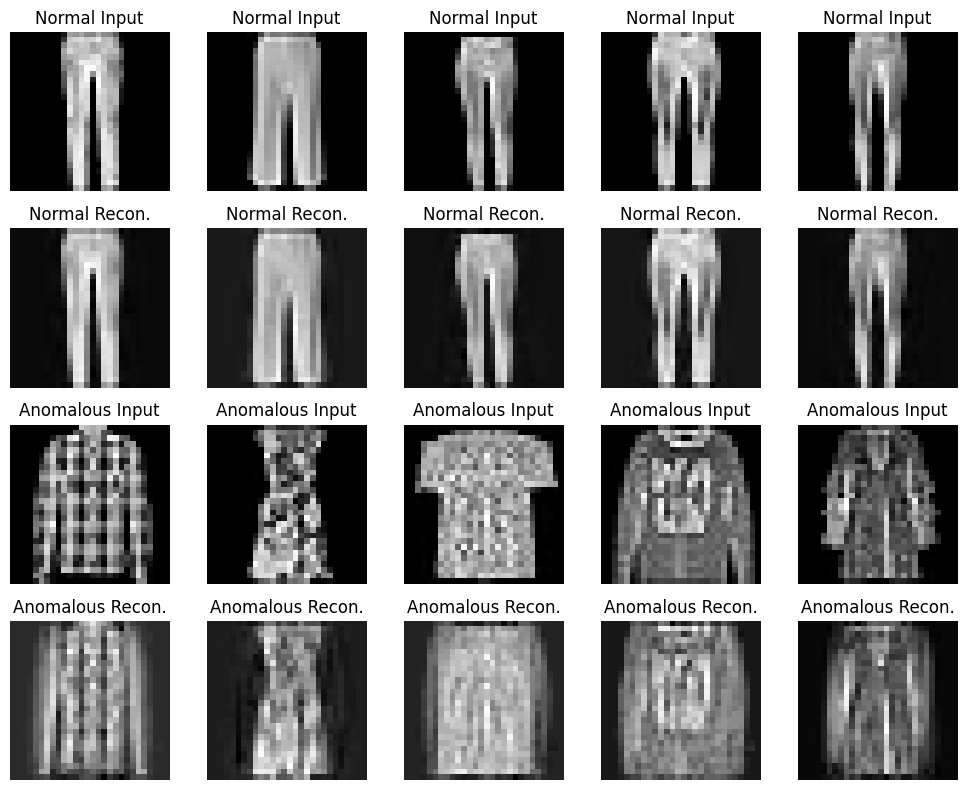

In [ ]:
# Create a test set with X% anomalies given by "anomaly_ratio"
n_anomalies = int(anomaly_ratio * len(x_test_class))

anomalous_indices = np.hstack([np.where(y_test == c)[0] for c in other_classes])
anomalous_samples = x_test_flat[np.random.choice(anomalous_indices, n_anomalies, replace=False)]

test_set_with_anomalies = np.vstack((x_test_class, anomalous_samples))
test_labels_with_anomalies = np.hstack((np.zeros(len(x_test_class)), np.ones(n_anomalies)))  # 0 for normal, 1 for anomaly

print('Mixed testset size:',len(test_labels_with_anomalies))

# Reconstruct the test set with anomalies
test_set_reconstructed = pca.inverse_transform(pca.transform(test_set_with_anomalies))

# Calculate reconstruction error for the test set with anomalies
test_mse_with_anomalies = mean_squared_error(test_set_with_anomalies, test_set_reconstructed)
print(f"Test MSE with anomalies: {test_mse_with_anomalies}")

# Visualize some normal and anomalous samples vs reconstructed images
n_images = 5
fig = plt.figure(figsize=(10, 8))

for i in range(n_images):
    # Original normal image
    plt.subplot(4, n_images, i + 1)
    plt.imshow(x_test_class[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Normal Input")

    # Reconstructed normal image
    plt.subplot(4, n_images, i + 1 + n_images)
    plt.imshow(x_test_reconstructed[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Normal Recon.")

for i in range(n_images):
    # Original anomalous image
    plt.subplot(4, n_images, i + 1 + 2 * n_images)
    plt.imshow(anomalous_samples[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Anomalous Input")

    # Reconstructed anomalous image
    plt.subplot(4, n_images, i + 1 + 3 * n_images)
    plt.imshow(test_set_reconstructed[len(x_test_class) + i].reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title("Anomalous Recon.")

plt.tight_layout()
plt.show()

#fig.savefig('fmnist_images_recon.pdf')  # Save the figure

# Download the figure
#from google.colab import files
#files.download('fmnist_images_recon.pdf')

In [ ]:
test_set_with_anomalies.shape

## Histogram of reconstruction errors

In [ ]:
# Calculate MSE for individual samples
train_mse_values = np.mean((x_train_class - x_train_reconstructed) ** 2, axis=1)
test_mse_values = np.mean((test_set_with_anomalies - test_set_reconstructed) ** 2, axis=1)

test_mse_anomalies = test_mse_values[test_labels_with_anomalies==1]
test_mse_normal = test_mse_values[test_labels_with_anomalies==0]

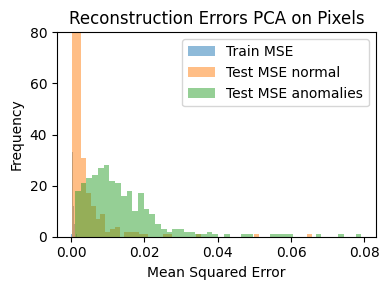

In [ ]:

# Plot histograms of MSE values
fig = plt.figure(figsize=(4, 3))
plt.hist(train_mse_values, bins=50, alpha=0.5, label="Train MSE")
plt.hist(test_mse_normal, bins=50,  alpha=0.5, label="Test MSE normal")
plt.hist(test_mse_anomalies, bins=50,  alpha=0.5, label="Test MSE anomalies")
plt.xlabel("Mean Squared Error")
plt.ylabel("Frequency")
plt.ylim(0,80)
plt.legend()
plt.title("Reconstruction Errors PCA on Pixels")

plt.tight_layout()
plt.show()
#fig.savefig('fmnist_hist_PCA_pixels.pdf')  # Save the figure

# Download the figure
#from google.colab import files
#files.download('fmnist_hist_PCA_pixels.pdf')

## Evaluation: precision recall curve

In [ ]:
# Apply Min-Max Normalization to the test scores
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import norm

scaler = MinMaxScaler()
normalized_scores = scaler.fit_transform(test_mse_values.reshape(-1, 1)).flatten()


In [ ]:
anomaly_scores = normalized_scores
true_labels = test_labels_with_anomalies

In [ ]:
precision_pca_raw, recall_pca_raw, _ = precision_recall_curve(true_labels, anomaly_scores)

<ipython-input-9-d5d3ce3c586e>:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


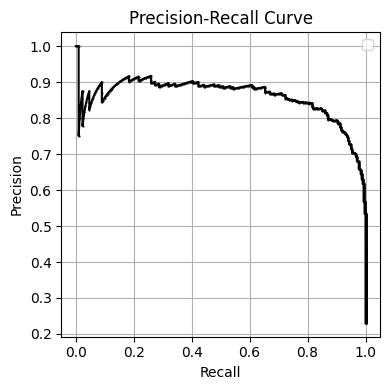

In [ ]:
plt.figure(figsize=(4, 4))
plt.plot(recall_pca_raw,precision_pca_raw,'k.-',ms=1)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid()

plt.tight_layout()
plt.legend()
plt.tight_layout()
#plt.savefig('prc_PCA_pixels_class1vsall_130PCs.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('prc_PCA_pixels_class1vsall_130PCs.pdf')

## Think
1. Can you extend the evaluation with a ROC plot?
2. Can you explain the performance? Hint: which is the normal class and which are the anomalies?
3. Can you design an "easier" AD task with the FMNIST data? a harder one?


# PCA on pretrained features
We use the ResNet152 model to extract a feature vector per image. We then use the feature vector as input to a PCA reconstruction model. We compare this model to the "raw pixels" model.

## Use ResNet representations for the visualisation of the Dataset

### Feature Extraction

let $X$ be the set of the original images $ \{x_{1},..,x_{n}\} $ with $x \in \mathbb{R}^{28x28}$. A pretrained  ResNet152$^{1}$ without the detectionhead  is used as a feature extractor $f_{\theta} : X → Z$ with $\theta$ = modelweights pretrained on the imagenet$^{2}$ dataset.
Let $ Z = \{ z_{1}, \dots, z_{n} \} $, where each $ z_{i} = f_{\theta}(x_{i}) \in \mathbb{R}^{d} $ and $d=2048$ is the dimensionality of the feature space extracted by the ResNet152 model. These high-dimensional feature vectors capture the abstract representations learned by the pretrained network.

<img src="https://github.com/buehlpa/Anomaly_Detection_Tutorial/blob/main/figures/f_extract.gif?raw=true" alt="feature extraction" width="700" >

### Dimensionality Reduction

To visualize how these features are distributed, we apply t-SNE$^{3}$ to the set $ Z $, reducing the dimensionality from $ d $ to a 2D space. This unsupervised dimensionality reduction allows us to observe clusters and patterns in the data, providing insights into the inherent structure of the feature space derived from the original images $ X $.


<img src="https://github.com/buehlpa/Anomaly_Detection_Tutorial/blob/main/figures/tsne2d.gif?raw=true" alt="tsne2d" width="700" >


$^{1}$=https://pytorch.org/hub/pytorch_vision_resnet/
$^{2}$=https://image-net.org/
$^{3}$=https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html













## Define train and test sets
Use the same
- selected_class
- train_indices
- test_indices
- anomalous_indices
- n_anomalies


as for the previous pixel-based model


In [ ]:
from tensorflow.keras.applications import ResNet152
from tensorflow.keras.applications.resnet import preprocess_input
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Input
from tensorflow.image import resize

In [ ]:

# Load Fashion MNIST data
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Do we want to accelerate the feature extraction by reducing the train and test set sizes?
reduce_size = True
if reduce_size:
    # Sample the training data to reduce size by a factor of 10
    #train_indices = np.random.choice(len(x_train), len(x_train) // 10, replace=False)
    #test_indices = np.random.choice(len(x_test), len(x_test) // 2, replace=False)
    x_train = x_train[train_indices]
    y_train = y_train[train_indices]
    x_test = x_test[test_indices]
    y_test = y_test[test_indices]

# Select a specific article class (e.g., class 0: T-shirts/tops, class 1:trousers)
#selected_class = 1
x_train_class = x_train[y_train == selected_class]

# Normalize and preprocess the training class for ResNet152
x_train_class = np.stack([np.stack([x] * 3, axis=-1) for x in x_train_class])
x_train_class = resize(x_train_class, [32, 32])
x_train_class = preprocess_input(x_train_class)

## Define test set with anomalies

In [ ]:
# Create a test set with  anomalies
x_test_class = x_test[y_test == selected_class] # majority class = normal
#n_anomalies = int(anom_ratio * len(x_test_class))
#other_classes = [c for c in range(10) if c != selected_class]
# anomalous_indices = np.hstack([np.where(y_test == c)[0] for c in other_classes])
anomalous_samples = x_test[np.random.choice(anomalous_indices, n_anomalies, replace=False)]

test_set_with_anomalies = np.vstack((x_test_class, anomalous_samples))
test_labels_with_anomalies = np.hstack((np.zeros(len(x_test_class)), np.ones(n_anomalies)))  # 0 for normal, 1 for anomaly

# Normalize and preprocess the test set for ResNet152
test_set_with_anomalies = np.stack([np.stack([x] * 3, axis=-1) for x in test_set_with_anomalies])
test_set_with_anomalies = resize(test_set_with_anomalies, [32, 32])
test_set_with_anomalies = preprocess_input(test_set_with_anomalies)

# print shapes of ResNet inputs
print('x_train_class:',x_train_class.shape,', test_set_with_anomalies:',test_set_with_anomalies.shape)

x_train_class: (605, 32, 32, 3) , test_set_with_anomalies: (1300, 32, 32, 3)


## Extract ResNet features for train and test set

In [ ]:
# Load ResNet152 model for feature extraction
base_model = ResNet152(weights="imagenet", include_top=False, input_shape=(32, 32, 3))
model = Model(inputs=base_model.input, outputs=GlobalAveragePooling2D()(base_model.output))

# Extract features ONLY for the normal class in training set
def extract_features(model, data):
    return model.predict(data, batch_size=64)

x_train_features = extract_features(model, x_train_class)

# Extract features ONLY for the final test set with anomalies
test_set_features = extract_features(model, test_set_with_anomalies)

# print feature shapes
print('x_train_features:',x_train_features.shape,', test_set_features:',test_set_features.shape)

10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 14s 659ms/step
x_train_features: (605, 2048) , test_set_features: (1300, 2048)


## Fit PCA on the extracted features

In [ ]:
# Fit PCA model on the selected class

#n_components = 130  # Number of principal components to keep
pca = PCA(n_components=n_components)
pca.fit(x_train_features)

# Transform the data to the PCA space and then back to reconstruct
x_train_pca = pca.transform(x_train_features)
x_train_reconstructed = pca.inverse_transform(x_train_pca)

x_test_pca = pca.transform(test_set_features)
x_test_reconstructed = pca.inverse_transform(x_test_pca)

## Calculate reconstruction errors

In [ ]:
# Calculate MSE for individual samples
train_mse_values = np.mean((x_train_features - x_train_reconstructed) ** 2, axis=1)
test_mse_values = np.mean((test_set_features - x_test_reconstructed) ** 2, axis=1)

test_mse_anomalies_pretrain = test_mse_values[test_labels_with_anomalies==1]
test_mse_normal_pretrain = test_mse_values[test_labels_with_anomalies==0]

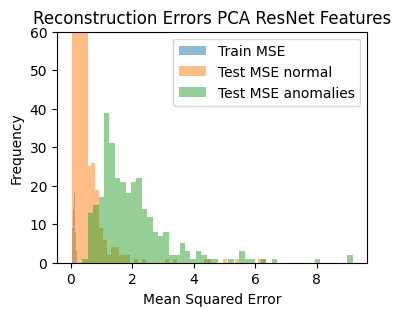

In [ ]:
# Calculate MSE for individual samples
#train_mse_values = np.mean((x_train_features - x_train_reconstructed) ** 2, axis=1)
#test_mse_values = np.mean((test_set_features - x_test_reconstructed) ** 2, axis=1)

# Plot histograms of MSE values
fig = plt.figure(figsize=(4, 3))
plt.hist(train_mse_values, bins=50, alpha=0.5, label="Train MSE")
plt.hist(test_mse_normal_pretrain, bins=50, alpha=0.5, label="Test MSE normal")
plt.hist(test_mse_anomalies_pretrain, bins=50, alpha=0.5, label="Test MSE anomalies")
plt.xlabel("Mean Squared Error")
plt.ylabel("Frequency")
plt.legend()
plt.ylim(0,60)
plt.title("Reconstruction Errors PCA ResNet Features")
plt.show()

#fig.savefig('fmnist_hist_recon_resnet.pdf')  # Save the figure

# Download the figure
#from google.colab import files
#files.download('fmnist_hist_recon_resnet.pdf')

## Plot reconstruction maps for normal and abnormal images

[0.16875985 0.4496083  0.2012428  0.21691543 0.28878522] [1.167586  2.0046923 3.5752435 1.7947774 3.7137794]


<ipython-input-18-bd37c94ef904>:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


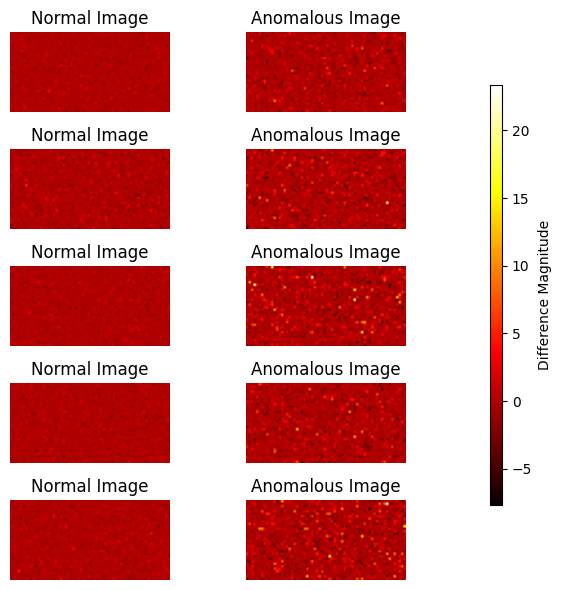

In [ ]:
# Select 5 normal and 5 anomalous images for visualization
normal_indices = np.where(test_labels_with_anomalies == 0)[0][:5]
anomalous_indices = np.where(test_labels_with_anomalies == 1)[0][:5]

print(test_mse_values[normal_indices],test_mse_values[anomalous_indices])
# Compute feature differences
normal_diffs = [(test_set_features[i] - x_test_reconstructed[i]) for i in normal_indices]
anomalous_diffs = [(test_set_features[i] - x_test_reconstructed[i]) for i in anomalous_indices]

# Determine common color scale
vmin = min(np.min(normal_diffs), np.min(anomalous_diffs))
vmax = max(np.max(normal_diffs), np.max(anomalous_diffs))

# Visualize heatmap of the difference between original and reconstructed features
fig, axes = plt.subplots(5, 2, figsize=(6, 6))
for i in range(5):
    im1 = axes[i, 0].imshow(normal_diffs[i].reshape(32, 64), cmap='hot', vmin=vmin, vmax=vmax)
    axes[i, 0].set_title("Normal Image")
    axes[i, 0].axis("off")

    im2 = axes[i, 1].imshow(anomalous_diffs[i].reshape(32, 64), cmap='hot', vmin=vmin, vmax=vmax)
    axes[i, 1].set_title("Anomalous Image")
    axes[i, 1].axis("off")

# Add a single colorbar for all subplots
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # Position: [left, bottom, width, height]
cbar = fig.colorbar(im1, cax=cbar_ax)
cbar.set_label("Difference Magnitude")

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

#fig.savefig('fmnist_featuremap_recon.pdf')  # Save the figure

# Download the figure
#from google.colab import files
#files.download('fmnist_featuremap_recon.pdf')

## Evaluation: precision recall curve

In [ ]:
# Apply Min-Max Normalization to the test scores
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import norm

scaler = MinMaxScaler()
normalized_scores = scaler.fit_transform(test_mse_values.reshape(-1, 1)).flatten()
anomaly_scores_pretrain = normalized_scores
true_labels_pretrain = test_labels_with_anomalies

In [ ]:
precision_pca_pretrain, recall_pca_pretrain, _ = precision_recall_curve(true_labels_pretrain, anomaly_scores_pretrain)

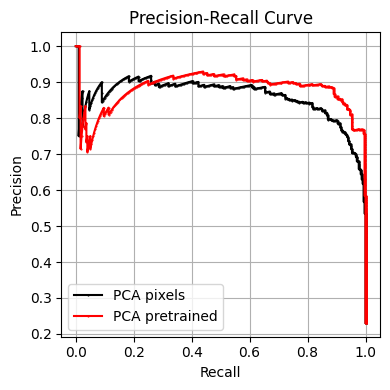

In [ ]:
plt.figure(figsize=(4, 4))
plt.plot(recall_pca_raw,precision_pca_raw,'k.-',ms=1,label='PCA pixels')
plt.plot(recall_pca_pretrain,precision_pca_pretrain,'r.-',ms=1,label='PCA pretrained')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid()

plt.legend()
plt.tight_layout()
#plt.savefig('prc_PCA_pixels_class1vsall_130PCs.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('prc_PCA_pixels_class1vsall_130PCs.pdf')

## investigate the model comparison
low recall = high false negative = many anomalies that are not detected = threshold is close to 1. we expect high precision = low false positive rate = that not many normal points have such a high anomaly score. Looks like this is not the case => many normal samples with a high score that lead to false positives together with false negatives.

In [ ]:
#true_normal_an_scores = anomaly_scores[true_labels==0]
#true_abnormal_an_scores = anomaly_scores[true_labels==1]
#true_normal_an_scores.shape[0]/anomaly_scores.shape[0],true_abnormal_an_scores.shape[0]/anomaly_scores.shape[0]


In [ ]:
#true_normal_an_scores_pret = anomaly_scores_pretrain[true_labels_pretrain==0]
#true_abnormal_an_scores_pret = anomaly_scores_pretrain[true_labels_pretrain==1]
#true_normal_an_scores_pret.shape[0]/anomaly_scores_pretrain.shape[0],true_abnormal_an_scores_pret.shape[0]/anomaly_scores_pretrain.shape[0]


In [ ]:
#plt.figure()
#plt.plot(np.sort(true_normal_an_scores),'.-',label='normal,pixels')
#plt.plot(np.sort(true_abnormal_an_scores),'.-',label='abnormal,pixels')

#plt.plot(np.sort(true_normal_an_scores_pret),'.-',label='normal,pretrained')
#plt.plot(np.sort(true_abnormal_an_scores_pret),'.-',label='abnormal,pretrained')
#plt.ylabel('normalized score')
#plt.legend()

In [ ]:
#plt.figure(figsize=(4,3))
#plt.hist(np.sort(true_normal_an_scores),50,label='normal,pixels',alpha=0.5)
#plt.hist(np.sort(true_abnormal_an_scores),50,label='abnormal,pixels',alpha=0.5)
#plt.ylim(0,60)
#plt.legend()
#plt.figure(figsize=(4,3))
#plt.hist(np.sort(true_normal_an_scores_pret),50,label='normal,pretrained',alpha=0.5)
#plt.hist(np.sort(true_abnormal_an_scores_pret),50,label='abnormal,pretrained',alpha=0.5)
#plt.xlabel('normalized score')
#plt.ylim(0,60)
#plt.legend()

# Autoencoder (AE) on pretrained features

In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dropout


# Define autoencoder model
encoding_dim = 128  # Dimensionality of encoded space
input_dim = x_train_features.shape[1]

autoencoder = Sequential([
    Input(shape=(input_dim,)),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),
    #Dropout(0.2),
    Dense(encoding_dim, activation='relu'),
    #Dropout(0.2),
    Dense(256, activation='relu'),
    Dense(512, activation='relu'),
    #Dropout(0.2),
    Dense(input_dim, activation='linear')
])


autoencoder.compile(optimizer=Adam(learning_rate=0.001), loss='mse')

# Train the autoencoder
autoencoder.fit(x_train_features, x_train_features, epochs=50, batch_size=64, shuffle=True, validation_split=0.2)


# Reconstruct train and test sets using the autoencoder
x_train_reconstructed = autoencoder.predict(x_train_features)
x_test_reconstructed = autoencoder.predict(test_set_features)

# Calculate reconstruction error for the test set with anomalies
test_mse_with_anomalies = mean_squared_error(test_set_features, x_test_reconstructed)
print(f"Test MSE with anomalies: {test_mse_with_anomalies}")




Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - loss: 7.1865 - val_loss: 4.1213
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 3.6908 - val_loss: 3.3284
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - loss: 3.0831 - val_loss: 2.6619
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - loss: 2.3406 - val_loss: 2.2009
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - loss: 2.0140 - val_loss: 1.9086
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - loss: 1.7752 - val_loss: 1.6932
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 1.5215 - val_loss: 1.5274
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 1.3498 - val_loss: 1.3954
Epoch 9/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 1.1670 - val_loss: 1.3012
Epoch 10/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 1.1496 - val_loss: 1.2139
Epoch 11/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 1.0216 - val_loss: 1.1342
Epoch 12/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.9434 - val_loss: 1.0644
E

## MSE for individual samples

In [ ]:
# Calculate MSE for individual samples
train_mse_values = np.mean((x_train_features - x_train_reconstructed) ** 2, axis=1)
test_mse_values = np.mean((test_set_features - x_test_reconstructed) ** 2, axis=1)


## Reconstruction error heatmaps

<ipython-input-24-920475bba394>:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


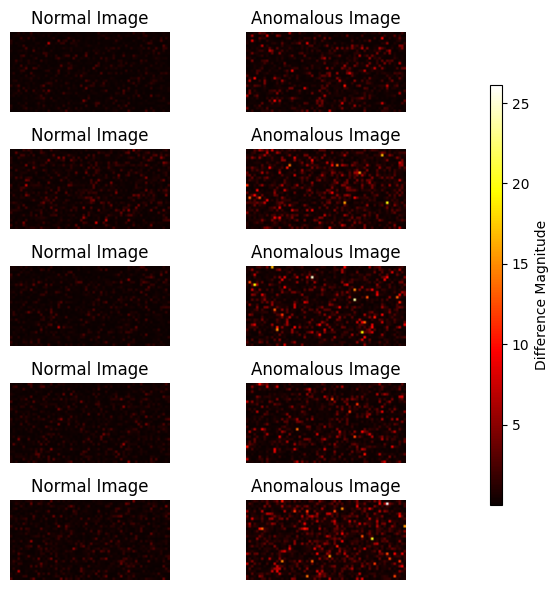

In [ ]:
# Select 5 normal and 5 anomalous images for visualization
normal_indices = np.where(test_labels_with_anomalies == 0)[0][:5]
anomalous_indices = np.where(test_labels_with_anomalies == 1)[0][:5]

# Compute feature differences
normal_diffs = [np.abs(test_set_features[i] - x_test_reconstructed[i]) for i in normal_indices]
anomalous_diffs = [np.abs(test_set_features[i] - x_test_reconstructed[i]) for i in anomalous_indices]

# Determine common color scale
vmin = min(np.min(normal_diffs), np.min(anomalous_diffs))
vmax = max(np.max(normal_diffs), np.max(anomalous_diffs))

# Visualize heatmap of the difference between original and reconstructed features
fig, axes = plt.subplots(5, 2, figsize=(6, 6))
for i in range(5):
    im1 = axes[i, 0].imshow(normal_diffs[i].reshape(32, 64), cmap='hot', vmin=vmin, vmax=vmax)
    axes[i, 0].set_title("Normal Image")
    axes[i, 0].axis("off")

    im2 = axes[i, 1].imshow(anomalous_diffs[i].reshape(32, 64), cmap='hot', vmin=vmin, vmax=vmax)
    axes[i, 1].set_title("Anomalous Image")
    axes[i, 1].axis("off")

# Add a single colorbar for all subplots
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # Position: [left, bottom, width, height]
cbar = fig.colorbar(im1, cax=cbar_ax)
cbar.set_label("Difference Magnitude")

plt.tight_layout(rect=[0, 0, 0.9, 1])
#plt.savefig('fmnist_reconerr_easy_AE_256_64_256.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('fmnist_reconerr_easy_AE_256_64_256.pdf')

## Evaluation: precision recall curve

In [ ]:
# Apply Min-Max Normalization to the test scores
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import norm

scaler = MinMaxScaler()
normalized_scores = scaler.fit_transform(test_mse_values.reshape(-1, 1)).flatten()
anomaly_scores_pretrain_AE = normalized_scores
true_labels_pretrain_AE = test_labels_with_anomalies

In [ ]:
precision_ae_pretrain, recall_ae_pretrain, _ = precision_recall_curve(true_labels_pretrain_AE, anomaly_scores_pretrain_AE)

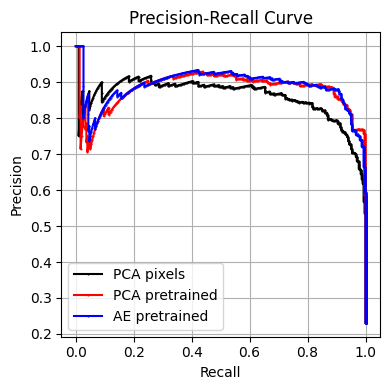

In [ ]:
plt.figure(figsize=(4, 4))
plt.plot(recall_pca_raw,precision_pca_raw,'k.-',ms=1,label='PCA pixels')
plt.plot(recall_pca_pretrain,precision_pca_pretrain,'r.-',ms=1,label='PCA pretrained')
plt.plot(recall_ae_pretrain,precision_ae_pretrain,'b.-',ms=1,label='AE pretrained')


plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid()

plt.legend()
plt.tight_layout()
#plt.savefig('prc_compare_pca130_ae128.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('prc_compare_pca130_ae128.pdf')

## Think

- According to the above PRC plot, what has more impact in this case: model or data?
- How could you investigate what each model learns? Hint: can you visualize?
